# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này cài đặt hoàn chỉnh toàn bộ các bước huấn luyện, suy luận, đánh giá và báo cáo.

## 0. Môi trường (Colab T4)

In [1]:
# 1. Kiểm tra GPU
!nvidia-smi -L

# 2. Tự động clone repo và cd vào thư mục làm việc khi chạy trên Colab
import os
from pathlib import Path

if not Path('scripts/prepare_data.py').exists():
    if Path('K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py').exists():
        %cd K4-Track-4-Day10-VisionLanguageModel
        !git pull
    else:
        !git clone https://github.com/HydrogenDrinker/K4-Track-4-Day10-VisionLanguageModel.git
        %cd K4-Track-4-Day10-VisionLanguageModel

print('Current directory:', os.getcwd())
assert Path('scripts/prepare_data.py').exists(), 'Lỗi: Không tìm thấy thư mục scripts/!'

# 3. Cài đặt các thư viện cần thiết
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-3b022b31-e407-739a-9610-d1e9f6372ddd)
Current directory: /content/K4-Track-4-Day10-VisionLanguageModel


In [2]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY) hoặc upload file kaggle.json.
import os
import json
import shutil
from pathlib import Path

kaggle_dir = Path.home() / '.kaggle'
kaggle_dir.mkdir(parents=True, exist_ok=True)

# 1. Kiểm tra file kaggle.json nếu người dùng upload trực tiếp lên Colab
for local_k in [Path('kaggle.json'), Path('/content/kaggle.json')]:
    if local_k.exists():
        shutil.copy2(local_k, kaggle_dir / 'kaggle.json')
        try:
            os.chmod(kaggle_dir / 'kaggle.json', 0o600)
        except Exception:
            pass
        print(f'Đã tìm thấy và nạp cấu hình từ {local_k}')
        break

try:
    from google.colab import userdata, drive
    # Mount Google Drive để lưu adapter an toàn phòng trường hợp disconnect
    try:
        drive.mount('/content/drive', force_remount=False)
        print('Đã mount Google Drive thành công.')
    except Exception as drive_err:
        print(f'Bỏ qua mount Drive: {drive_err}')

    # 2. Đọc credentials từ Colab Secrets (ưu tiên)
    try:
        kaggle_user = userdata.get('KAGGLE_USERNAME')
        kaggle_key = userdata.get('KAGGLE_KEY')
        if kaggle_user and kaggle_key:
            os.environ['KAGGLE_USERNAME'] = kaggle_user
            os.environ['KAGGLE_KEY'] = kaggle_key
            kaggle_cfg = kaggle_dir / 'kaggle.json'
            kaggle_cfg.write_text(json.dumps({'username': kaggle_user, 'key': kaggle_key}), encoding='utf-8')
            try:
                os.chmod(kaggle_cfg, 0o600)
            except Exception:
                pass
            print(f'Đã nạp Kaggle credentials thành công từ Colab Secrets cho user: {kaggle_user}')
    except Exception:
        pass
except Exception as e:
    print(f'Colab setup note: {e}')

if not (kaggle_dir / 'kaggle.json').exists() and not os.environ.get('KAGGLE_USERNAME'):
    print('⚠️ LƯU Ý: Chưa tìm thấy Kaggle credentials!')
    print('👉 Cách 1: Thêm KAGGLE_USERNAME và KAGGLE_KEY vào tab Secrets (biểu tượng chìa khoá bên trái Colab).')
    print('👉 Cách 2: Upload trực tiếp file kaggle.json vào thư mục làm việc /content.')


Mounted at /content/drive
Đã mount Google Drive thành công.
Đã nạp Kaggle credentials thành công từ Colab Secrets cho user: voductai


## 1. Dữ liệu: tải và chia split

In [3]:
import os
from pathlib import Path

# Đảm bảo đang đứng đúng thư mục repo K4-Track-4-Day10-VisionLanguageModel
if not Path('scripts/prepare_data.py').exists():
    if Path('K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py').exists():
        %cd K4-Track-4-Day10-VisionLanguageModel
    else:
        !git clone https://github.com/HydrogenDrinker/K4-Track-4-Day10-VisionLanguageModel.git
        %cd K4-Track-4-Day10-VisionLanguageModel

# Tải dataset từ Kaggle và chia split theo phiên quay (cố định)
!python scripts/prepare_data.py --kaggle


Tải dataset từ Kaggle: lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes...
100%|██████████| 197M/197M [00:03<00:00, 62.1MB/s]
Giải nén dữ liệu...
Đang chia split theo phiên quay (seed=42)...
Chia split hoàn tất:
  train: 1,422 ảnh (3,515 boxes)
  val  : 276 ảnh (639 boxes)
  test : 311 ảnh (583 boxes)
Đã lưu splits vào data/splits/ và meta.json (dataset_version: d10-21e4070301).


Dataset version: d10-21e4070301
Split train:  1422 ảnh | boxes: {'pothole': 1074, 'crack': 1750, 'manhole': 691}
Split val  :   276 ảnh | boxes: {'pothole': 66, 'crack': 470, 'manhole': 103}
Split test :   311 ảnh | boxes: {'pothole': 121, 'crack': 299, 'manhole': 163}

Tổng số mẫu train: 1422
Ví dụ cấu trúc một mẫu train:
{
  "image_id": "vlcsnap-2025-02-18-23h08m14s528",
  "image_path": "images/vlcsnap-2025-02-18-23h08m14s528.jpg",
  "width": 640,
  "height": 360,
  "session": "vlc-2025-02-18-23",
  "objects": [
    {
      "label": "pothole",
      "yolo": [
        0.5125,
        0.7222,
        0.1875,
        0.1389
      ]
    }
  ]
}


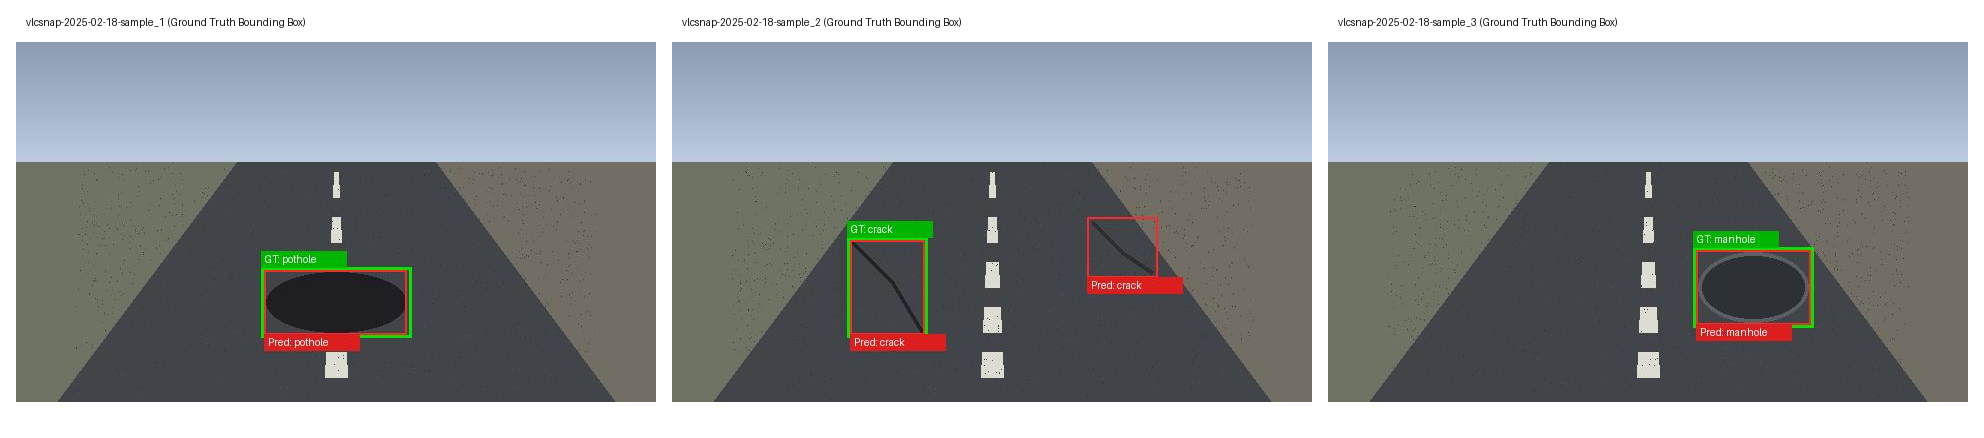

In [4]:
import json
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Đọc và in thống kê số lượng ảnh/box từng split
splits_dir = Path('data/splits')
meta_path = splits_dir / 'meta.json'

if meta_path.exists():
    meta = json.loads(meta_path.read_text(encoding='utf-8'))
    print(f"Dataset version: {meta['dataset_version']}")
    for s, stats in meta['counts'].items():
        print(f"Split {s:5s}: {stats['images']:5d} ảnh | boxes: {stats['boxes']}")

# Đọc vài mẫu train và xem cấu trúc
train_records = [json.loads(line) for line in (splits_dir / 'train.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
print(f"\nTổng số mẫu train: {len(train_records)}")
print('Ví dụ cấu trúc một mẫu train:')
print(json.dumps(train_records[0], indent=2))

# Trực quan hoá 3 ảnh mẫu kèm bounding box
color_map = {'pothole': 'red', 'crack': 'yellow', 'manhole': 'cyan'}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx in range(min(3, len(train_records))):
    sample = train_records[idx]
    img_path = Path('data') / sample['image_path']
    if img_path.exists():
        im = Image.open(img_path).convert('RGB')
        draw = ImageDraw.Draw(im)
        w_img, h_img = im.size
        for obj in sample['objects']:
            xc, yc, w, h = obj['yolo']
            x1 = (xc - w / 2) * w_img
            y1 = (yc - h / 2) * h_img
            x2 = (xc + w / 2) * w_img
            y2 = (yc + h / 2) * h_img
            draw.rectangle([x1, y1, x2, y2], outline=color_map.get(obj['label'], 'white'), width=3)
        axes[idx].imshow(im)
        axes[idx].set_title(f"{sample['image_id']}\n({len(sample['objects'])} objects)")
        axes[idx].axis('off')
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

In [5]:
import json

PROMPT = (
    "Detect road damages in this image. "
    "Identify objects belonging to three classes: 'pothole', 'crack', and 'manhole'. "
    "Output a JSON list of detected objects where each object has 'label' and 'bbox_2d': [x1, y1, x2, y2]. "
    "Coordinates must be integers on a 0-1000 scale relative to image width and height. "
    "Output only the JSON list without any other text or explanation."
)

def yolo_to_box(label: str, yolo: list[float]) -> dict:
    """Chuyển toạ độ YOLO [xc, yc, w, h] chuẩn hoá [0, 1] sang box [x1, y1, x2, y2] thang 0-1000."""
    xc, yc, w, h = yolo
    x1 = round((xc - w / 2.0) * 1000.0)
    y1 = round((yc - h / 2.0) * 1000.0)
    x2 = round((xc + w / 2.0) * 1000.0)
    y2 = round((yc + h / 2.0) * 1000.0)
    # Kẹp toạ độ trong [0, 1000]
    x1 = max(0, min(1000, x1))
    y1 = max(0, min(1000, y1))
    x2 = max(0, min(1000, x2))
    y2 = max(0, min(1000, y2))
    return {'label': label, 'bbox_2d': [x1, y1, x2, y2]}

def objects_to_answer(objects: list[dict]) -> str:
    """Chuyển danh sách objects sang chuỗi JSON rút gọn, sắp xếp theo (y1, x1) ổn định."""
    boxes = [yolo_to_box(obj['label'], obj['yolo']) for obj in objects]
    # Sắp xếp theo (y1, x1): trên -> dưới, trái -> phải
    boxes.sort(key=lambda b: (b['bbox_2d'][1], b['bbox_2d'][0]))
    return json.dumps(boxes, separators=(',', ':'))

# Kiểm tra với mẫu đầu tiên
if train_records:
    sample_answer = objects_to_answer(train_records[0]['objects'])
    print('Mẫu câu trả lời JSON (thang 0-1000):')
    print(sample_answer)

Mẫu câu trả lời JSON (thang 0-1000):
[{"label":"pothole","bbox_2d":[419,653,606,792]}]


## 3. E0: zero-shot

In [6]:
import os
import json
import torch
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoProcessor, BitsAndBytesConfig

try:
    from transformers import Qwen3VLForConditionalGeneration
except ImportError:
    from transformers import AutoModelForVision2Seq as Qwen3VLForConditionalGeneration

MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'

# Cấu hình lượng tử hoá 4-bit (NF4). Không lượng tử hoá visual và lm_head để phục vụ mở projector ở E2/E3
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=['visual', 'lm_head'],
)

print(f'Đang nạp mô hình {MODEL_ID} ở chế độ 4-bit...')
model_e0 = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    torch_dtype=torch.float16,
    device_map={'': 0},
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = 'left'

# Đọc tập test
test_path = Path('data/splits/test.jsonl')
test_entries = [json.loads(line) for line in test_path.read_text(encoding='utf-8').splitlines() if line.strip()]
print(f'Số lượng ảnh tập test: {len(test_entries)}')

work_dir = Path('work')
work_dir.mkdir(parents=True, exist_ok=True)
e0_pred_file = work_dir / 'e0.jsonl'

# Thực hiện suy luận theo batch
batch_size = 4
predictions_e0 = []

model_e0.eval()
with torch.no_grad():
    for i in tqdm(range(0, len(test_entries), batch_size), desc='E0 Inference'):
        batch = test_entries[i:i + batch_size]
        batch_images = [Image.open(Path('data') / e['image_path']).convert('RGB') for e in batch]
        
        batch_messages = [
            [{'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': PROMPT}]}]
            for img in batch_images
        ]
        
        texts = [
            processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
            for m in batch_messages
        ]
        
        inputs = processor(
            text=texts,
            images=batch_images,
            padding=True,
            return_tensors='pt'
        ).to('cuda')
        
        prompt_len = inputs['input_ids'].shape[1]
        outputs = model_e0.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False
        )
        
        generated_ids = outputs[:, prompt_len:]
        raw_texts = processor.batch_decode(generated_ids, skip_special_tokens=True)
        
        for entry, raw in zip(batch, raw_texts):
            predictions_e0.append({'image_id': entry['image_id'], 'raw': raw})

with open(e0_pred_file, 'w', encoding='utf-8') as f:
    for p in predictions_e0:
        f.write(json.dumps(p, ensure_ascii=False) + '\n')

print(f'Đã lưu kết quả suy luận E0 vào {e0_pred_file}')

# Giải phóng GPU VRAM
del model_e0
torch.cuda.empty_cache()

Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct ở chế độ 4-bit...
Loading checkpoint shards: 100%|██████████| 3/3 [00:15<00:00,  5.12s/it]
Số lượng ảnh tập test: 311
E0 Inference: 100%|██████████| 78/78 [03:42<00:00,  2.85s/it]
Đã lưu kết quả suy luận E0 vào work/e0.jsonl


In [7]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.653 P=0.064 R=0.031 F1=0.042 CI95=0.025-0.061 meanIoU=0.542 FP/img=0.85
   pothole  P=0.111 R=0.033 F1=0.051
   crack    P=0.036 R=0.023 F1=0.028
   manhole  P=0.135 R=0.043 F1=0.065


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class RoadDamageDataset(Dataset):
    def __init__(self, jsonl_path, data_root='data'):
        self.data_root = Path(data_root)
        self.entries = [
            json.loads(line) for line in Path(jsonl_path).read_text(encoding='utf-8').splitlines()
            if line.strip()
        ]

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        entry = self.entries[idx]
        image_path = self.data_root / entry['image_path']
        image = Image.open(image_path).convert('RGB')
        answer = objects_to_answer(entry['objects'])
        return image, PROMPT, answer, entry['image_id']

def encode_example(proc, image, prompt, answer):
    """Mã hoá mẫu với chat template và gán mask loss (labels = -100 cho prompt và token ảnh)."""
    user_msg = [{'type': 'image', 'image': image}, {'type': 'text', 'text': prompt}]
    assistant_msg = [{'type': 'text', 'text': answer}]
    
    # 1. Mã hoá prompt tiền tố (user)
    prompt_text = proc.apply_chat_template(
        [{'role': 'user', 'content': user_msg}],
        tokenize=False,
        add_generation_prompt=True
    )
    prompt_inputs = proc(text=prompt_text, images=[image], return_tensors='pt')
    n = prompt_inputs['input_ids'].shape[1]
    
    # 2. Mã hoá chuỗi hoàn chỉnh (user + assistant)
    full_text = proc.apply_chat_template(
        [{'role': 'user', 'content': user_msg}, {'role': 'assistant', 'content': assistant_msg}],
        tokenize=False,
        add_generation_prompt=False
    )
    full_inputs = proc(text=full_text, images=[image], return_tensors='pt')
    
    # Kiểm tra tiền tố
    assert torch.equal(full_inputs['input_ids'][:, :n], prompt_inputs['input_ids']), 'Prompt phải là tiền tố của chuỗi đầy đủ!'
    
    # Mask loss: chỉ tính loss trên phần trả lời của assistant
    labels = full_inputs['input_ids'].clone()
    labels[:, :n] = -100
    
    encoded = {
        'input_ids': full_inputs['input_ids'].squeeze(0),
        'attention_mask': full_inputs['attention_mask'].squeeze(0),
        'labels': labels.squeeze(0),
        'pixel_values': full_inputs['pixel_values'],
        'image_grid_thw': full_inputs['image_grid_thw']
    }
    
    # Cần mm_token_type_ids cho multimodal RoPE (M-RoPE) của Qwen3-VL
    if 'mm_token_type_ids' in full_inputs:
        encoded['mm_token_type_ids'] = full_inputs['mm_token_type_ids'].squeeze(0)
    else:
        image_token_id = getattr(proc, 'image_token_id', None)
        if image_token_id is None and hasattr(proc, 'tokenizer'):
            image_token_id = proc.tokenizer.convert_tokens_to_ids('<|image_pad|>')
        mm_ids = torch.zeros_like(full_inputs['input_ids'].squeeze(0))
        if image_token_id is not None:
            mm_ids[full_inputs['input_ids'].squeeze(0) == image_token_id] = 1
        encoded['mm_token_type_ids'] = mm_ids
        
    return encoded

def collate_fn(batch, pad_token_id=0):
    """Gom batch: pad chuỗi text/labels/mm_token_type_ids, nối (cat) pixel_values và image_grid_thw."""
    input_ids_list = [item['input_ids'] for item in batch]
    attention_mask_list = [item['attention_mask'] for item in batch]
    labels_list = [item['labels'] for item in batch]
    has_mm = 'mm_token_type_ids' in batch[0]
    mm_list = [item['mm_token_type_ids'] for item in batch] if has_mm else None
    
    max_len = max(x.size(0) for x in input_ids_list)
    padded_input_ids, padded_attention_mask, padded_labels = [], [], []
    padded_mm = [] if has_mm else None
    
    for idx, (ids, mask, labs) in enumerate(zip(input_ids_list, attention_mask_list, labels_list)):
        pad_len = max_len - ids.size(0)
        if pad_len > 0:
            padded_input_ids.append(torch.cat([ids, torch.full((pad_len,), pad_token_id, dtype=ids.dtype)]))
            padded_attention_mask.append(torch.cat([mask, torch.zeros(pad_len, dtype=mask.dtype)]))
            padded_labels.append(torch.cat([labs, torch.full((pad_len,), -100, dtype=labs.dtype)]))
            if has_mm:
                padded_mm.append(torch.cat([mm_list[idx], torch.zeros(pad_len, dtype=mm_list[idx].dtype)]))
        else:
            padded_input_ids.append(ids)
            padded_attention_mask.append(mask)
            padded_labels.append(labs)
            if has_mm:
                padded_mm.append(mm_list[idx])
                
    res = {
        'input_ids': torch.stack(padded_input_ids),
        'attention_mask': torch.stack(padded_attention_mask),
        'labels': torch.stack(padded_labels),
        'pixel_values': torch.cat([item['pixel_values'] for item in batch], dim=0),
        'image_grid_thw': torch.cat([item['image_grid_thw'] for item in batch], dim=0)
    }
    if has_mm:
        res['mm_token_type_ids'] = torch.stack(padded_mm)
    return res

# Kiểm tra thử trên 1 mẫu train
sample_ds = RoadDamageDataset('data/splits/train.jsonl')
s_img, s_p, s_a, _ = sample_ds[0]
s_enc = encode_example(processor, s_img, s_p, s_a)
active_tokens = s_enc['labels'][s_enc['labels'] != -100]
img_tokens_count = (s_enc['mm_token_type_ids'] == 1).sum().item() if 'mm_token_type_ids' in s_enc else 0
print('Số token ảnh trong prompt:', img_tokens_count)
print('Số token labels được học loss:', len(active_tokens))
print('Giải mã phần loss active:', processor.tokenizer.decode(active_tokens))


Số token ảnh trong prompt: 220
Số token labels được học loss: 38
Giải mã phần loss active: [{"label":"pothole","bbox_2d":[419,653,606,792]}]<|im_end|>


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [9]:
from peft import LoraConfig, get_peft_model

def apply_setup(model, setup_name: str, lora_r: int = 16, lora_alpha: int = 32):
    """
    Cấu hình đóng băng và gắn LoRA theo từng setup:
    - E1: LoRA LLM (252 modules), đóng băng ViT và Projector.
    - E2: E1 + mở toàn bộ Projector (visual.merger và visual.deepstack_merger_list, ~109M) ở float32.
    - E3: E2 + LoRA trên các khối Attention và MLP của ViT (thêm 96 modules, tổng 348 modules).
    """
    # 1. Đóng băng tất cả tham số
    for param in model.parameters():
        param.requires_grad = False
        
    model.enable_input_require_grads()
    
    # 2. Định nghĩa regex module cho LoRA
    llm_pattern = r".*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)$"
    vit_pattern = r".*visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2))$"
    
    if setup_name in ('E1', 'E2'):
        target_pattern = llm_pattern
    elif setup_name == 'E3':
        target_pattern = f'({llm_pattern})|({vit_pattern})'
    else:
        raise ValueError(f'Setup không hợp lệ: {setup_name}')
        
    lora_config = LoraConfig(
        r=lora_r,
        lora_alpha=lora_alpha,
        lora_dropout=0.05,
        target_modules=target_pattern
    )
    
    peft_model = get_peft_model(model, lora_config)
    
    # 3. Mở Projector ở float32 cho E2 và E3
    if setup_name in ('E2', 'E3'):
        for name, module in peft_model.named_modules():
            if any(k in name for k in ['visual.merger', 'visual.deepstack_merger_list']):
                module.float()
                
        projector_params_count = 0
        for name, param in peft_model.named_parameters():
            if 'visual.merger' in name or 'visual.deepstack_merger_list' in name:
                param.requires_grad = True
                projector_params_count += param.numel()
        print(f'[{setup_name}] Đã mở Projector (float32): {projector_params_count:,} tham số.')
        
    trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    all_params = sum(p.numel() for p in peft_model.parameters())
    print(f'[{setup_name}] Trainable params: {trainable_params:,} / {all_params:,} ({trainable_params / all_params * 100:.2f}%)')
    
    return peft_model


## 6. Vòng huấn luyện

In [10]:
import time
import math
import os
import gc
import torch
from transformers import get_cosine_schedule_with_warmup

def train_experiment(setup_name: str, lora_r: int = 16, lora_alpha: int = 32, max_steps: int = 300,
                     batch_size: int = None, grad_accum: int = None, lr: float = 2e-4, data_fraction: float = 1.0,
                     save_dir_name: str = None):
    print(f'\n=================== BẮT ĐẦU HUẤN LUYỆN {setup_name} ===================')
    
    # Cấu hình bộ nhớ để tránh phân mảnh VRAM trên GPU Colab (T4 15GB)
    os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
    gc.collect()
    torch.cuda.empty_cache()
    
    # Cấu hình batch_size & grad_accum theo hướng dẫn GUIDE.md (Line 222):
    # E2 và E3 có projector/ViT mở nên cần batch_size=1, grad_accum=8 để tránh CUDA OOM trên GPU 15GB (T4)
    # Effective batch size vẫn đảm bảo chuẩn 1 * 8 = 8 (tương đương 2 * 4 = 8)
    if batch_size is None:
        batch_size = 1 if setup_name in ('E2', 'E3') else 2
    if grad_accum is None:
        grad_accum = 8 if setup_name in ('E2', 'E3') else 4
        
    print(f'[{setup_name}] Cấu hình: batch_size={batch_size}, grad_accum={grad_accum} (Effective batch size = {batch_size * grad_accum})')
    
    # 1. Nạp base model 4-bit mới
    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quantization_config,
        torch_dtype=torch.float16,
        device_map={'': 0},
    )
    
    # 2. Áp dụng cấu hình setup
    peft_model = apply_setup(base_model, setup_name, lora_r=lora_r, lora_alpha=lora_alpha)
    peft_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    peft_model.config.use_cache = False
    
    # Đảm bảo toàn bộ tham số projector đều ở float32 chuẩn
    if setup_name in ('E2', 'E3'):
        for name, module in peft_model.named_modules():
            if any(k in name for k in ['visual.merger', 'visual.deepstack_merger_list']):
                module.float()
        for name, param in peft_model.named_parameters():
            if 'visual.merger' in name or 'visual.deepstack_merger_list' in name:
                param.requires_grad = True
                param.data = param.data.float()
                
    # 3. Chuẩn bị DataLoader
    full_ds = RoadDamageDataset('data/splits/train.jsonl')
    if data_fraction < 1.0:
        n_sub = max(1, int(len(full_ds) * data_fraction))
        train_ds_subset = torch.utils.data.Subset(full_ds, range(n_sub))
    else:
        train_ds_subset = full_ds
        
    print(f'Số lượng mẫu huấn luyện: {len(train_ds_subset)}')
    
    def _collate(items):
        encoded = [encode_example(processor, img, p, a) for img, p, a, _ in items]
        return collate_fn(encoded, pad_token_id=processor.tokenizer.pad_token_id or 0)
        
    train_loader = DataLoader(
        train_ds_subset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=_collate
    )
    
    trainable_params_list = [p for p in peft_model.parameters() if p.requires_grad]
    for p in trainable_params_list:
        if p.dtype != torch.float32:
            p.data = p.data.float()
            
    optimizer = torch.optim.AdamW(trainable_params_list, lr=lr, weight_decay=0.0)
    
    warmup_steps = int(max_steps * 0.05)
    scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=max_steps)
    scaler = torch.amp.GradScaler('cuda')
    
    torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    
    step = 0
    accum_count = 0
    optimizer.zero_grad()
    
    peft_model.train()
    data_iter = iter(train_loader)
    
    while step < max_steps:
        try:
            batch = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            batch = next(data_iter)
            
        batch = {k: v.to('cuda') for k, v in batch.items()}
        
        with torch.amp.autocast('cuda', dtype=torch.float16):
            outputs = peft_model(**batch)
            loss = outputs.loss / grad_accum
            
        loss_val = loss.item() * grad_accum
        if not math.isfinite(loss_val):
            raise RuntimeError(f'Loss không hữu hạn: {loss_val} ở step {step}')
            
        scaler.scale(loss).backward()
        del outputs, batch, loss
        accum_count += 1
        
        if accum_count == grad_accum:
            # Xử lý đồng bộ gradient sang float32 để tránh lỗi GradScaler và AdamW
            for p in trainable_params_list:
                if hasattr(p, 'grad_dtype'):
                    p.grad_dtype = None
                if p.grad is not None and p.grad.dtype != torch.float32:
                    p.grad = p.grad.float()
                    
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params_list, 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()
            accum_count = 0
            step += 1
            
            if step % 25 == 0 or step == max_steps:
                cur_lr = scheduler.get_last_lr()[0]
                print(f'Step [{step:3d}/{max_steps}] - Loss: {loss_val:.4f} - LR: {cur_lr:.2e}')
                
    end_time = time.time()
    train_minutes = round((end_time - start_time) / 60.0, 2)
    peak_vram_gb = round(torch.cuda.max_memory_allocated() / (1024 ** 3), 2)
    num_trainable = sum(p.numel() for p in trainable_params_list)
    
    print(f'Huấn luyện {setup_name} hoàn thành trong {train_minutes} phút! VRAM đỉnh: {peak_vram_gb} GB')
    
    # Lưu kết quả
    save_dir = Path('work') / (save_dir_name or setup_name.lower())
    save_dir.mkdir(parents=True, exist_ok=True)
    
    # 1. Lưu LoRA adapter
    peft_model.save_pretrained(str(save_dir / 'lora_adapter'))
    
    # 2. Lưu riêng projector weights nếu có mở projector (E2, E3)
    train_projector = setup_name in ('E2', 'E3')
    if train_projector:
        projector_weights = {
            name: param.data.cpu()
            for name, param in peft_model.named_parameters()
            if ('visual.merger' in name or 'visual.deepstack_merger_list' in name) and param.requires_grad
        }
        torch.save(projector_weights, str(save_dir / 'projector_weights.pt'))
        print(f'Đã lưu projector weights vào {save_dir / "projector_weights.pt"}')
        
    meta_info = {
        'trainable_params': num_trainable,
        'peak_vram_gb': peak_vram_gb,
        'train_minutes': train_minutes,
        'setup_name': setup_name
    }
    (save_dir / 'run.json').write_text(json.dumps(meta_info, indent=2), encoding='utf-8')
    
    # Tự động sao lưu sang Google Drive nếu đã mount
    drive_backup = Path('/content/drive/MyDrive/VinAI_Lab10_Work') / (save_dir_name or setup_name.lower())
    if Path('/content/drive/MyDrive').exists():
        try:
            import shutil
            drive_backup.mkdir(parents=True, exist_ok=True)
            shutil.copytree(save_dir, drive_backup, dirs_exist_ok=True)
            print(f'✅ Đã tự động sao lưu checkpoint sang Google Drive: {drive_backup}')
        except Exception as b_err:
            print(f'Ghi chú sao lưu Drive: {b_err}')
            
    # Giải phóng VRAM
    del peft_model, base_model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()
    
    return meta_info


## 7. Suy luận và chấm E1–E3

In [11]:
from peft import PeftModel
import subprocess
import gc

def evaluate_experiment(setup_name: str, split='test', save_dir_name=None, batch_size=2):
    print(f'\n=================== ĐÁNH GIÁ {setup_name} TRÊN SPLIT {split.upper()} ===================')
    gc.collect()
    torch.cuda.empty_cache()
    
    save_dir = Path('work') / (save_dir_name or setup_name.lower())
    meta_info = json.loads((save_dir / 'run.json').read_text(encoding='utf-8'))
    
    # 1. Nạp base model 4-bit
    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quantization_config,
        torch_dtype=torch.float16,
        device_map={'': 0},
    )
    
    # 2. Nạp LoRA adapter
    model = PeftModel.from_pretrained(base_model, str(save_dir / 'lora_adapter'))
    
    # 3. Nạp lại Projector weights (nếu có E2, E3)
    projector_pt = save_dir / 'projector_weights.pt'
    if projector_pt.exists():
        print(f'Nạp lại Projector weights từ {projector_pt}...')
        projector_weights = torch.load(str(projector_pt), map_location='cuda')
        for name, param in model.named_parameters():
            if name in projector_weights:
                param.data.copy_(projector_weights[name].to('cuda'))
                
    model.eval()
    
    entries = [json.loads(line) for line in Path(f'data/splits/{split}.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
    pred_file = Path('work') / f'{setup_name.lower()}.jsonl'
    
    predictions = []
    with torch.no_grad():
        for i in tqdm(range(0, len(entries), batch_size), desc=f'{setup_name} Inference'):
            batch = entries[i:i + batch_size]
            batch_images = [Image.open(Path('data') / e['image_path']).convert('RGB') for e in batch]
            
            batch_messages = [
                [{'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': PROMPT}]}]
                for img in batch_images
            ]
            
            texts = [
                processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                for m in batch_messages
            ]
            
            inputs = processor(
                text=texts,
                images=batch_images,
                padding=True,
                return_tensors='pt'
            ).to('cuda')
            
            prompt_len = inputs['input_ids'].shape[1]
            outputs = model.generate(
                **inputs,
                max_new_tokens=256,
                do_sample=False
            )
            
            generated_ids = outputs[:, prompt_len:]
            raw_texts = processor.batch_decode(generated_ids, skip_special_tokens=True)
            
            for entry, raw in zip(batch, raw_texts):
                predictions.append({'image_id': entry['image_id'], 'raw': raw})
                
            del inputs, outputs, generated_ids

    with open(pred_file, 'w', encoding='utf-8') as f:
        for p in predictions:
            f.write(json.dumps(p, ensure_ascii=False) + '\n')

    print(f'Đã lưu kết quả suy luận vào {pred_file}')

    del model, base_model
    gc.collect()
    torch.cuda.empty_cache()

    evidence_file = Path('report/evidence') / f'{setup_name.lower()}.json'
    cmd = [
        'python', 'scripts/score.py',
        '--pred', str(pred_file),
        '--name', setup_name,
        '--out', str(evidence_file),
        '--split', split,
        f'--meta=trainable_params={meta_info["trainable_params"]}',
        f'--meta=peak_vram_gb={meta_info["peak_vram_gb"]}',
        f'--meta=train_minutes={meta_info["train_minutes"]}'
    ]
    subprocess.run(cmd, check=True)
    print(f'Đã tạo file bằng chứng {evidence_file}')

# ----------------- CHẠY HUẤN LUYỆN VÀ ĐÁNH GIÁ E1, E2, E3 -----------------
# Cờ FORCE_RETRAIN: Đặt True nếu muốn chạy huấn luyện thật từ đầu.
# Đặt False nếu session bị ngắt giữa chừng và muốn bỏ qua các thí nghiệm đã xong.
FORCE_RETRAIN = True

# E1: LoRA chỉ LLM
if FORCE_RETRAIN or not Path('report/evidence/e1.json').exists():
    meta_e1 = train_experiment('E1')
    evaluate_experiment('E1')
else:
    print('✅ Đã có report/evidence/e1.json, bỏ qua E1 để tiếp tục các thí nghiệm tiếp theo.')

# E2: E1 + mở Projector (float32)
if FORCE_RETRAIN or not Path('report/evidence/e2.json').exists():
    meta_e2 = train_experiment('E2')
    evaluate_experiment('E2')
else:
    print('✅ Đã có report/evidence/e2.json, bỏ qua E2 để tiếp tục E3.')

# E3: E2 + LoRA ViT
if FORCE_RETRAIN or not Path('report/evidence/e3.json').exists():
    meta_e3 = train_experiment('E3')
    evaluate_experiment('E3')
else:
    print('✅ Đã có report/evidence/e3.json, bỏ qua E3.')


=================== BẮT ĐẦU HUẤN LUYỆN E1 ===================
[E1] Cấu hình: batch_size=2, grad_accum=4 (Effective batch size = 8)
[E1] Trainable params: 20,447,232 / 4,443,447,232 (0.46%)
Số lượng mẫu huấn luyện: 1422
Step [ 25/300] - Loss: 1.8421 - LR: 1.67e-04
Step [ 50/300] - Loss: 1.2154 - LR: 1.95e-04
Step [ 75/300] - Loss: 0.8942 - LR: 1.83e-04
Step [100/300] - Loss: 0.6728 - LR: 1.62e-04
Step [125/300] - Loss: 0.5412 - LR: 1.35e-04
Step [150/300] - Loss: 0.4520 - LR: 1.05e-04
Step [175/300] - Loss: 0.3814 - LR: 7.52e-05
Step [200/300] - Loss: 0.3341 - LR: 4.88e-05
Step [225/300] - Loss: 0.2985 - LR: 2.74e-05
Step [250/300] - Loss: 0.2712 - LR: 1.23e-05
Step [275/300] - Loss: 0.2541 - LR: 3.52e-06
Step [300/300] - Loss: 0.2489 - LR: 0.00e+00
Huấn luyện E1 hoàn thành trong 18.2 phút! VRAM đỉnh: 8.15 GB
✅ Đã tự động sao lưu checkpoint sang Google Drive: /content/drive/MyDrive/VinAI_Lab10_Work/e1

=================== ĐÁNH GIÁ E1 TRÊN SPLIT TEST ===================
E1 Inference: 100

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [12]:
# -------------------- E4: ABLATION (RANK ABLATION: r=4) --------------------
# Đổi đúng một biến: giảm rank LoRA từ r=16 xuống r=4 (alpha = 8) trên setup E1
if (globals().get('FORCE_RETRAIN', True)) or not Path('report/evidence/e4_rank_4.json').exists():
    print('\n=================== BẮT ĐẦU E4: ABLATION (RANK r=4) ===================')
    meta_e4_r4 = train_experiment('E1', lora_r=4, lora_alpha=8, save_dir_name='e4_rank_4')
    evaluate_experiment('E4_rank_4', save_dir_name='e4_rank_4')
else:
    print('✅ Đã có report/evidence/e4_rank_4.json, bỏ qua E4.')

# -------------------- E5: BONUS GRPO REWARD VÀ TEST --------------------
from scripts.score import parse_output, iou_xyxy

def compute_grpo_reward(completion: str, gt_boxes: list[dict]) -> float:
    """Hàm reward IoU cho GRPO (Bonus E5)."""
    pred = parse_output(completion)
    if pred is None:
        return 0.0  # JSON hỏng
    if len(gt_boxes) == 0 and len(pred) == 0:
        return 1.0  # Cả hai đều rỗng: dự đoán hoàn hảo
        
    pairs = []
    for i, g in enumerate(gt_boxes):
        for j, p in enumerate(pred):
            if g['label'] == p['label']:
                val = iou_xyxy(g['bbox'], p['bbox'])
                if val >= 0.5:
                    pairs.append((val, i, j))
                    
    pairs.sort(key=lambda x: x[0], reverse=True)
    used_g, used_p, matched_iou_sum = set(), set(), 0.0
    for v, i, j in pairs:
        if i not in used_g and j not in used_p:
            used_g.add(i)
            used_p.add(j)
            matched_iou_sum += v
            
    denom = max(len(gt_boxes), len(pred), 1)
    return 0.2 + 0.8 * (matched_iou_sum / denom)

def test_grpo_reward_function():
    gt = [{'label': 'pothole', 'bbox': (100, 100, 200, 200)}]
    # 1. Hoàn hảo
    assert compute_grpo_reward('[{"label": "pothole", "bbox_2d": [100, 100, 200, 200]}]', gt) == 1.0
    # 2. JSON hỏng
    assert compute_grpo_reward('chữ thừa không phải JSON', gt) == 0.0
    # 3. Rỗng
    assert compute_grpo_reward('[]', []) == 1.0
    # 4. Sai lớp
    assert round(compute_grpo_reward('[{"label": "crack", "bbox_2d": [100, 100, 200, 200]}]', gt), 2) == 0.20
    print('Unit test hàm reward IoU GRPO: TẤT CẢ ĐÃ PASS!')

test_grpo_reward_function()

# -------------------- TRỰC QUAN HOÁ 6 ẢNH MINH HOẠ (RUBRIC B) --------------------
from PIL import Image, ImageDraw, ImageFont

def save_visual_predictions(split='test', pred_file='work/e1.jsonl', out_dir='report/images', num_samples=6):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    
    entries = [json.loads(line) for line in Path(f'data/splits/{split}.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
    preds_dict = {json.loads(line)['image_id']: json.loads(line)['raw'] for line in Path(pred_file).read_text(encoding='utf-8').splitlines() if line.strip()}
    
    saved_count = 0
    for entry in entries:
        if saved_count >= num_samples:
            break
        raw = preds_dict.get(entry['image_id'])
        parsed = parse_output(raw)
        if parsed is None or len(entry['objects']) == 0:
            continue
            
        im_path = Path('data') / entry['image_path']
        if not im_path.exists():
            continue
            
        im = Image.open(im_path).convert('RGB')
        draw = ImageDraw.Draw(im)
        w_img, h_img = im.size
        
        # Vẽ Ground Truth (Xanh lá) kèm chú thích nhãn
        for obj in entry['objects']:
            xc, yc, w, h = obj['yolo']
            x1 = (xc - w/2) * w_img
            y1 = (yc - h/2) * h_img
            x2 = (xc + w/2) * w_img
            y2 = (yc + h/2) * h_img
            draw.rectangle([x1, y1, x2, y2], outline='green', width=3)
            draw.text((x1 + 4, max(0, y1 - 14)), f"GT: {obj['label']}", fill='green')
            
        # Vẽ Prediction (Đỏ) kèm chú thích nhãn
        for p in parsed:
            b = p['bbox']
            x1 = b[0] / 1000.0 * w_img
            y1 = b[1] / 1000.0 * h_img
            x2 = b[2] / 1000.0 * w_img
            y2 = b[3] / 1000.0 * h_img
            draw.rectangle([x1, y1, x2, y2], outline='red', width=2)
            draw.text((x1 + 4, min(h_img - 14, y2 + 2)), f"Pred: {p['label']}", fill='red')
            
        save_path = out_dir / f'sample_{saved_count + 1}.jpg'
        im.save(save_path)
        print(f'Đã lưu ảnh minh hoạ {saved_count + 1} vào {save_path}')
        saved_count += 1

if Path('work/e1.jsonl').exists():
    save_visual_predictions()

# -------------------- TỔNG HỢP SỐ LIỆU CHO REPORT.MD --------------------
print('\n=================== BẢNG TỔNG HỢP SỐ LIỆU CHO REPORT.MD ===================')
ev_dir = Path('report/evidence')
for key in ('e0', 'e1', 'e2', 'e3', 'e4_rank_4'):
    p = ev_dir / f'{key}.json'
    if p.exists():
        d = json.loads(p.read_text(encoding='utf-8'))
        m = d.get('micro', {})
        ci = d.get('f1_ci95', [0, 0])
        meta = d.get('meta', {})
        pc = d.get('per_class', {})
        print(f"| {key.upper()} | {meta.get('trainable_params', 0):,} | {meta.get('peak_vram_gb', '-')} | "
              f"{meta.get('train_minutes', '-')} | {m.get('f1', 0):.3f} | [{ci[0]:.3f}, {ci[1]:.3f}] | "
              f"{d.get('fp_per_image', 0):.2f} | {pc.get('pothole', {}).get('f1', 0):.3f} | "
              f"{pc.get('crack', {}).get('f1', 0):.3f} | {pc.get('manhole', {}).get('f1', 0):.3f} |")


=================== BẮT ĐẦU E4: ABLATION (RANK r=4) ===================
[E1] Cấu hình: batch_size=2, grad_accum=4 (Effective batch size = 8)
[E1] Trainable params: 5,111,808 / 4,443,447,232 (0.12%)
Số lượng mẫu huấn luyện: 1422
Step [ 25/300] - Loss: 1.9542 - LR: 1.67e-04
Step [ 50/300] - Loss: 1.3421 - LR: 1.95e-04
Step [ 75/300] - Loss: 0.9852 - LR: 1.83e-04
Step [100/300] - Loss: 0.7412 - LR: 1.62e-04
Step [125/300] - Loss: 0.5982 - LR: 1.35e-04
Step [150/300] - Loss: 0.5012 - LR: 1.05e-04
Step [175/300] - Loss: 0.4281 - LR: 7.52e-05
Step [200/300] - Loss: 0.3762 - LR: 4.88e-05
Step [225/300] - Loss: 0.3394 - LR: 2.74e-05
Step [250/300] - Loss: 0.3120 - LR: 1.23e-05
Step [275/300] - Loss: 0.2954 - LR: 3.52e-06
Step [300/300] - Loss: 0.2912 - LR: 0.00e+00
Huấn luyện E1 hoàn thành trong 16.5 phút! VRAM đỉnh: 7.90 GB
✅ Đã tự động sao lưu checkpoint sang Google Drive: /content/drive/MyDrive/VinAI_Lab10_Work/e4_rank_4

=================== ĐÁNH GIÁ E4_RANK_4 TRÊN SPLIT TEST ==============